In [ ]:
# Import required libraries

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

# Load the training dataset

df = pd.read_csv('/train.csv')

# Keep a copy of the original dataset

df_original = df.copy()

# Define target variable

target = 'satisfaction'

# Define categorical features

cat = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

# Define numerical features

num = [

    'Age',

    'Flight Distance',

    'Departure Delay in Minutes',

    'Arrival Delay in Minutes'

]

# Define service rating features

identifier_cols = ['Unnamed: 0', 'id']

rate = [

    c for c in df.columns

    if c not in cat + num + [target] + identifier_cols

]
# Display dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")

print(df.columns.tolist())

print("\nFirst 5 Rows:")

display(df.head())

Dataset Shape: (103904, 25)

Column Names:
['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

First 5 Rows:


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:
# بدايه كود نوره

In [ ]:
# Exploratory Data Analysis(EDA)

satisfaction
neutral or dissatisfied    56.666731
satisfied                  43.333269
Name: proportion, dtype: float64


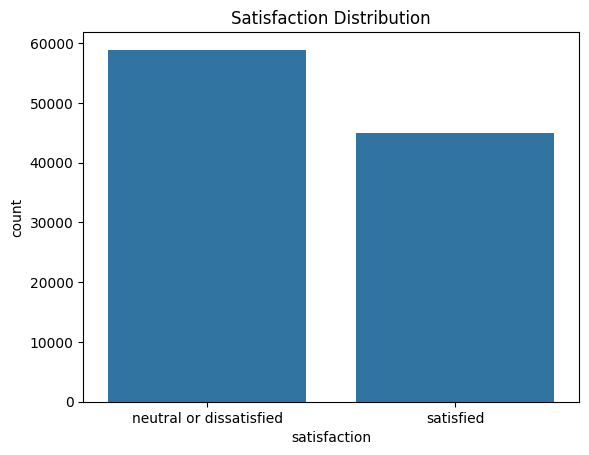

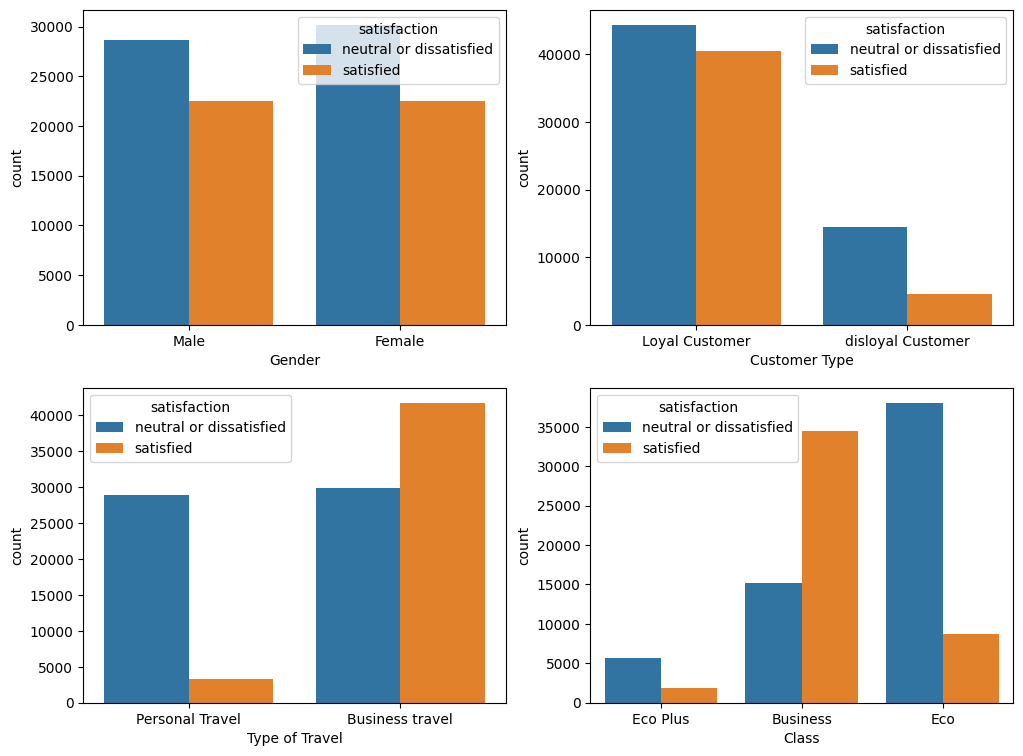

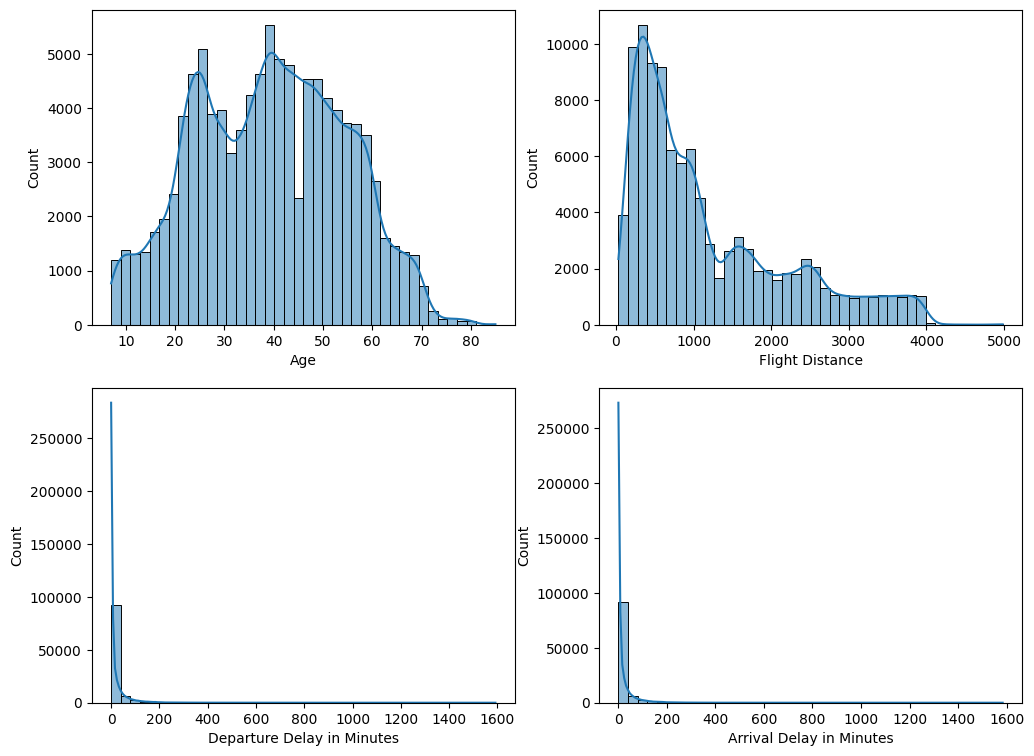

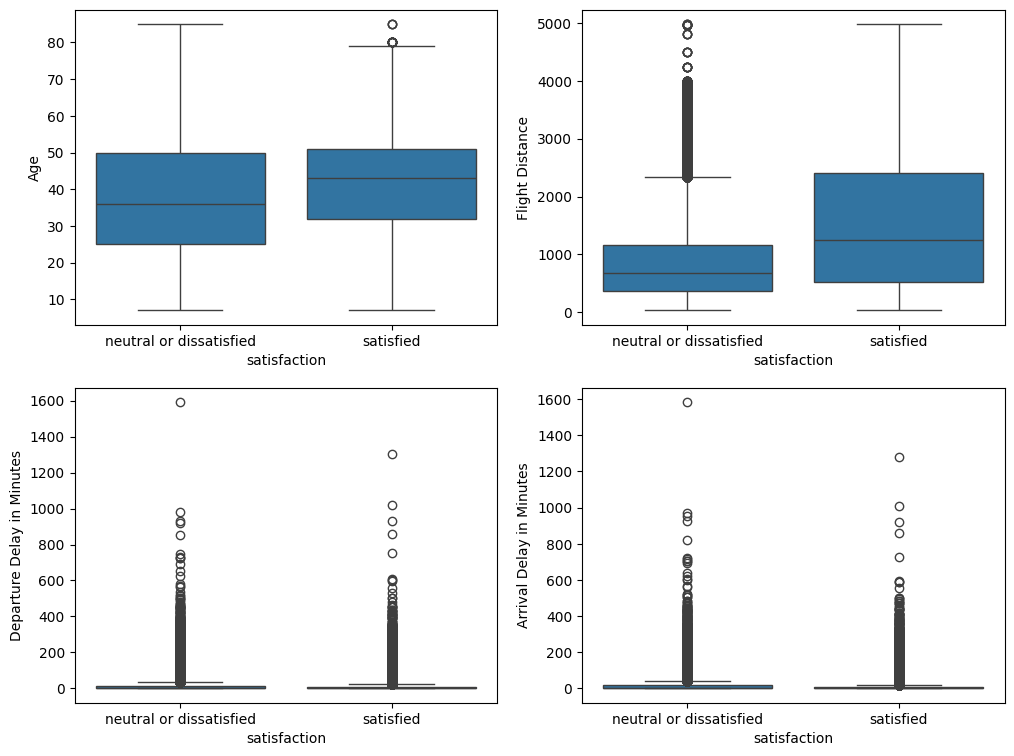

satisfaction                       neutral or dissatisfied  satisfied  diff
Online boarding                                       2.66       4.03  1.37
Inflight entertainment                                2.89       3.96  1.07
Seat comfort                                          3.04       3.97  0.93
On-board service                                      3.02       3.86  0.84
Leg room service                                      2.99       3.82  0.83
Cleanliness                                           2.94       3.74  0.81
Inflight wifi service                                 2.40       3.16  0.76
Checkin service                                       3.04       3.65  0.60
Baggage handling                                      3.38       3.97  0.59
Inflight service                                      3.39       3.97  0.58
Food and drink                                        2.96       3.52  0.56
Ease of Online booking                                2.55       3.03  0.48
Gate locatio

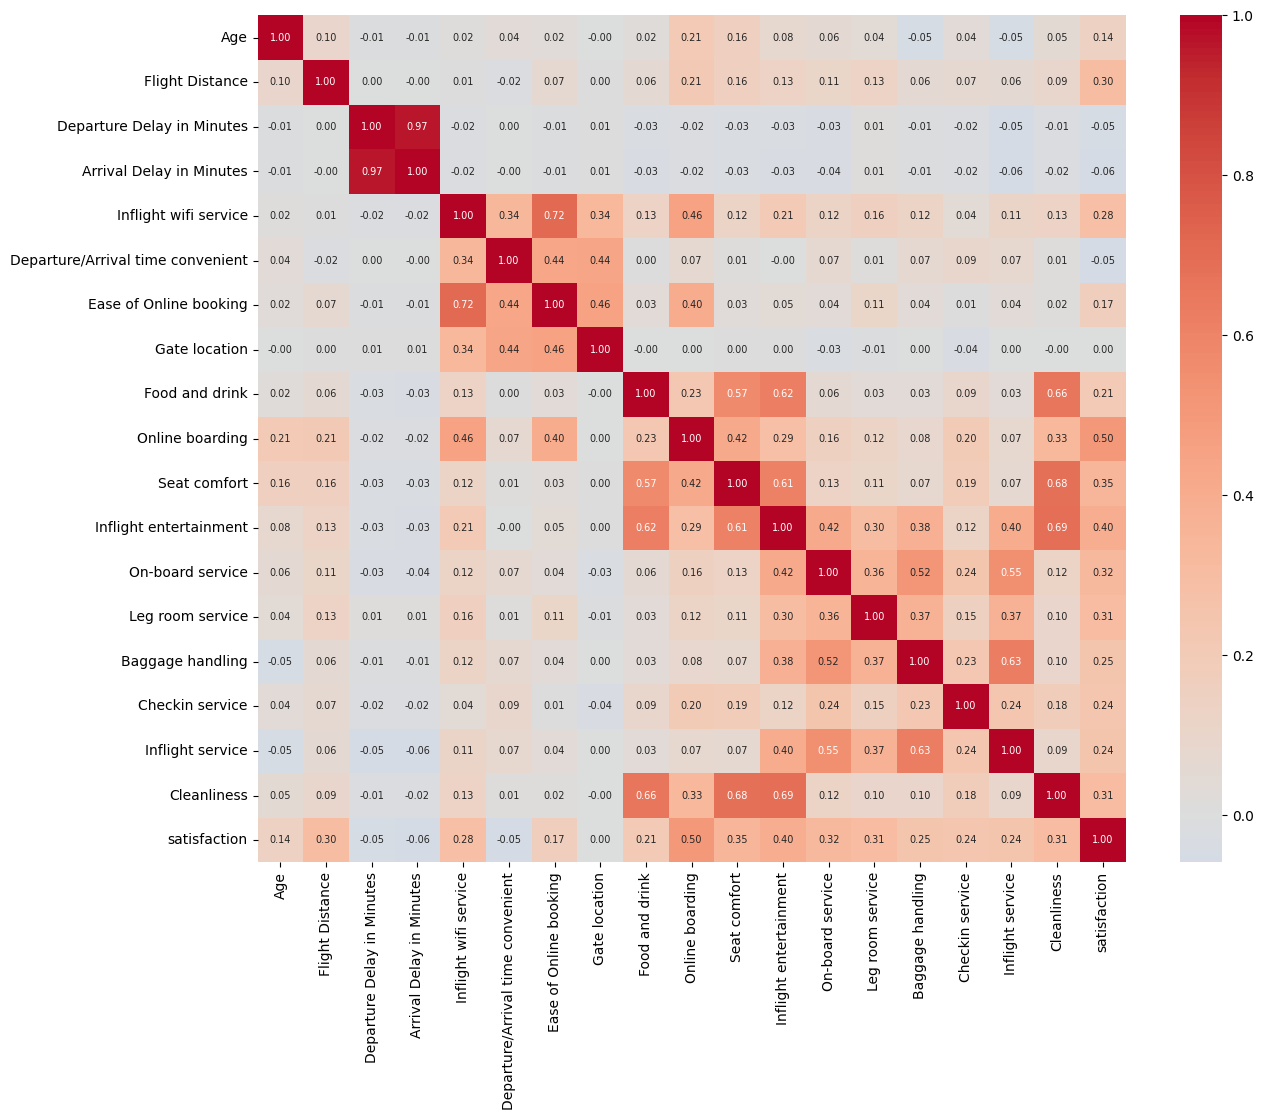

Online boarding                      0.504
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Ease of Online booking               0.172
Age                                  0.137
Arrival Delay in Minutes            -0.058
Departure/Arrival time convenient   -0.052
Departure Delay in Minutes          -0.050
Gate location                        0.001
Name: satisfaction, dtype: float64


In [ ]:
# Target distribution
print(df[target].value_counts(normalize=True) * 100)
sns.countplot(data=df, x=target)
plt.title('Satisfaction Distribution')
plt.show()

# Categorical features vs satisfaction
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for a, c in zip(ax.ravel(), cat):
    sns.countplot(data=df, x=c, hue=target, ax=a)
plt.show()

# Numerical distributions
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for a, c in zip(ax.ravel(), num):
    sns.histplot(df[c], bins=40, kde=True, ax=a)
plt.show()

# Numerical features vs satisfaction
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for a, c in zip(ax.ravel(), num):
    sns.boxplot(data=df, x=target, y=c, ax=a)
plt.show()

# Rating gap between satisfied and neutral/dissatisfied
avg = df.groupby(target)[rate].mean().T
avg['diff'] = avg['satisfied'] - avg['neutral or dissatisfied']
print(avg.sort_values('diff', ascending=False).round(2))

# Correlation heatmap
t = df.copy()
t[target] = (t[target] == 'satisfied').astype(int)
corr = t[num + rate + [target]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.show()

# Features most correlated with satisfaction
print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

In [ ]:
# Missing Values Analysis

                          Missing      %
Arrival Delay in Minutes      310  0.298


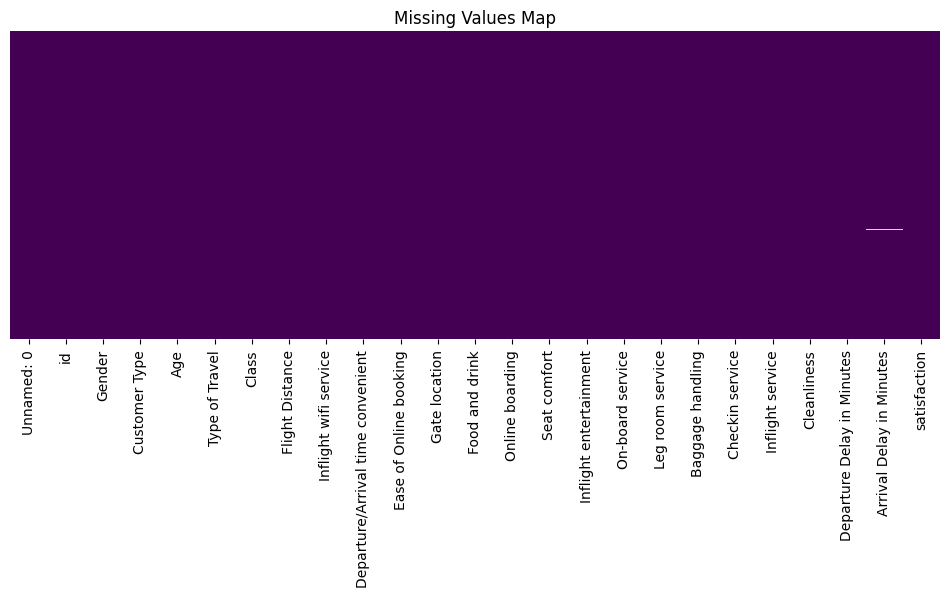

Arrival Delay in Minutes
False    14.747939
True     37.432258
Name: Departure Delay in Minutes, dtype: float64
satisfaction              neutral or dissatisfied  satisfied
Arrival Delay in Minutes                                    
False                                        56.7       43.3
True                                         58.7       41.3


In [ ]:
# Count and percentage of missing values
m = df.isnull().sum()
print(pd.DataFrame({'Missing': m, '%': (m / len(df) * 100).round(3)}).query('Missing > 0'))

# Missing values map
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Map')
plt.show()

# Is the missingness related to delay or satisfaction?
mask = df['Arrival Delay in Minutes'].isnull()
print(df.groupby(mask)['Departure Delay in Minutes'].mean())
print(pd.crosstab(mask, df[target], normalize='index').round(3) * 100)

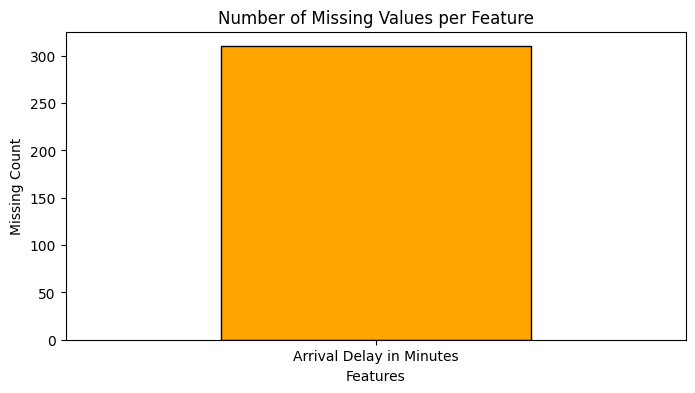

In [ ]:
plt.figure(figsize=(8, 4))
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

missing_data.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Number of Missing Values per Feature')
plt.xlabel('Features')
plt.ylabel('Missing Count')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# نهايه كود نوره

In [ ]:
# JOOD
# OUTLIER ANALYSIS

# Numerical features to analyze

numerical_features = [

    'Age',

    'Flight Distance',

    'Departure Delay in Minutes',

    'Arrival Delay in Minutes'

]

# Detect outliers using the IQR method

outlier_results = []

for col in numerical_features:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({

        'Feature': col,

        'Lower Bound': round(lower_bound, 2),

        'Upper Bound': round(upper_bound, 2),

        'Outlier Count': len(outliers),

        'Outlier Percentage': round(len(outliers) / len(df) * 100, 2)

    })

# Display results

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,-9.0,87.0,0,0.00
1,Flight Distance,-1579.5,3736.5,2291,2.20
2,Departure Delay in Minutes,-18.0,30.0,14529,13.98
3,Arrival Delay in Minutes,-19.5,32.5,13954,13.43


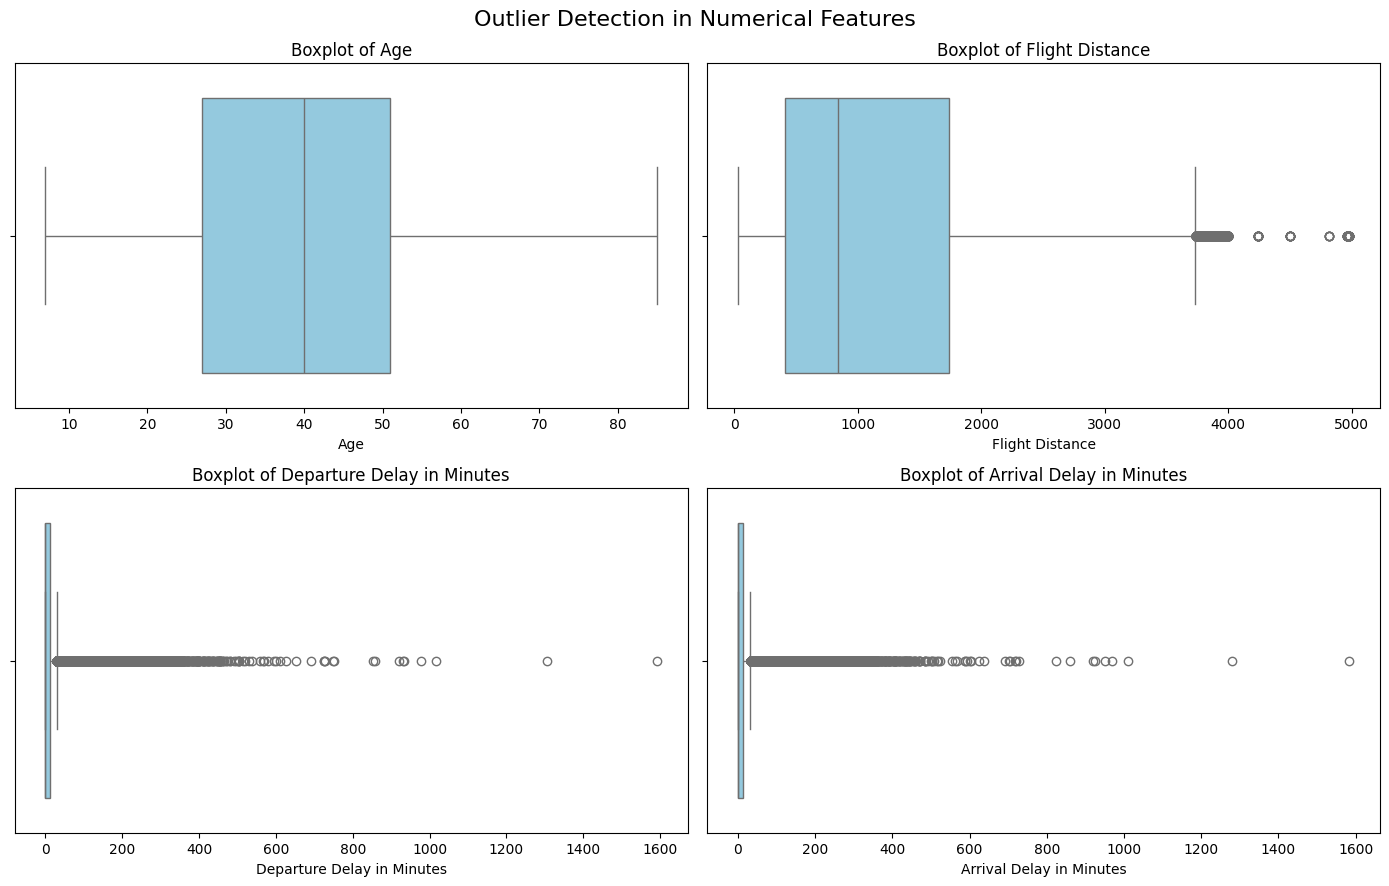

In [ ]:
# OUTLIER VISUALIZATION
#JOOD


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), numerical_features):

    sns.boxplot(x=df[col], ax=ax, color='skyblue')

    ax.set_title(f'Boxplot of {col}')

    ax.set_xlabel(col)

plt.suptitle('Outlier Detection in Numerical Features', fontsize=16)

plt.tight_layout()

plt.show()

In [ ]:
# DATA QUALITY CHECK
#JOOD


# Check minimum and maximum values

print("Minimum and Maximum Values:")

display(df[numerical_features].agg(['min', 'max']))

# Check duplicate rows

print("\nNumber of duplicate rows:")

print(df.duplicated().sum())

# Check invalid values

print("\nInvalid Values Check:")

print("Negative ages:", (df['Age'] < 0).sum())

print("Negative flight distances:",

      (df['Flight Distance'] < 0).sum())

print("Negative departure delays:",

      (df['Departure Delay in Minutes'] < 0).sum())

print("Negative arrival delays:",

      (df['Arrival Delay in Minutes'] < 0).sum())

# Check missing values

print("\nMissing Values:")

display(df.isnull().sum()[df.isnull().sum() > 0])

Minimum and Maximum Values:


,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
min,7,31,0,0.0
max,85,4983,1592,1584.0



Number of duplicate rows:
0

Invalid Values Check:
Negative ages: 0
Negative flight distances: 0
Negative departure delays: 0
Negative arrival delays: 0

Missing Values:


,0
Arrival Delay in Minutes,310


In [ ]:

# DATA CLEANING - MISSING VALUES CHECK
#JOOD


print("Dataset shape before cleaning:", df.shape)

print("\nMissing values in each column:")

print(df.isnull().sum())

print("\nTotal missing values:")

print(df.isnull().sum().sum())

print("\nMissing values percentage:")

print((df.isnull().mean() * 100).round(2))

Dataset shape before cleaning: (103904, 25)

Missing values in each column:
Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Min

In [ ]:
# DATA CLEANING
#JOOD

# Create a copy to preserve the original dataset

df_clean = df.copy()

print("Dataset shape before cleaning:", df_clean.shape)

# 1. Remove duplicate rows

df_clean = df_clean.drop_duplicates()

# 2. Handle missing values using the median

median_arrival_delay = df_clean['Arrival Delay in Minutes'].median()

df_clean['Arrival Delay in Minutes'] = (

    df_clean['Arrival Delay in Minutes'].fillna(median_arrival_delay)

)

# 3. Keep valid outliers

# Extreme flight distances and delays may represent real flights.

# Therefore, no outlier removal or capping is applied.

# 4. Verify the cleaning results

print("\nDataset shape after cleaning:", df_clean.shape)

print("\nRemaining missing values:",

      df_clean.isnull().sum().sum())

print("Remaining duplicate rows:",

      df_clean.duplicated().sum())

print("\nMedian used for Arrival Delay:",

      median_arrival_delay)

print("\nCleaned Dataset Preview:")

display(df_clean.head())

Dataset shape before cleaning: (103904, 25)

Dataset shape after cleaning: (103904, 25)

Remaining missing values: 0
Remaining duplicate rows: 0

Median used for Arrival Delay: 0.0

Cleaned Dataset Preview:


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:

#encoding and feature scaling

from sklearn.preprocessing import StandardScaler

# 1. Remove identifier columns
df_model = df_clean.drop(columns=identifier_cols).copy()

# 2. Target Encoding
df_model[target] = (df_model[target] == 'satisfied').astype(int)

# 3. Categorical Encoding
df_model['Gender'] = df_model['Gender'].map({
    'Male': 0,
    'Female': 1
})

df_model['Customer Type'] = df_model['Customer Type'].map({
    'disloyal Customer': 0,
    'Loyal Customer': 1
})

df_model['Type of Travel'] = df_model['Type of Travel'].map({
    'Personal Travel': 0,
    'Business travel': 1
})

df_model['Class'] = df_model['Class'].map({
    'Eco': 0,
    'Eco Plus': 1,
    'Business': 2
})

# 4. Feature Scaling
scaler = StandardScaler()

df_model.loc[:, num] = scaler.fit_transform(df_model[num])

# 5. Display results
print("Dataset shape:", df_model.shape)
print("\nTarget distribution:")
print(df_model[target].value_counts())

display(df_model.head())


Dataset shape: (103904, 23)

Target distribution:
satisfaction
0    58879
1    45025
Name: count, dtype: int64


/tmp/ipykernel_1067/1400411925.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-1.7452793  -0.95136024 -0.88520032 ... -0.62056063 -1.14984
 -0.8190404 ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_model.loc[:, num] = scaler.fit_transform(df_model[num])
/tmp/ipykernel_1067/1400411925.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.73153876 -0.95718354 -0.04758435 ...  0.8078601  -0.18999128
  0.53508063]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_model.loc[:, num] = scaler.fit_transform(df_model[num])
/tmp/ipykernel_1067/1400411925.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.26639265 -0.36137482 -0.3875318  ... -0.20443295 -0.3875318
 -0.3875318 ]' 

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,-1.745279,0,1,-0.731539,3,4,3,1,...,5,4,3,4,4,5,5,0.266393,0.074169,0
1,0,0,-0.951360,1,2,-0.957184,3,2,3,3,...,1,1,5,3,1,4,1,-0.361375,-0.236313,0
2,1,1,-0.885200,1,2,-0.047584,2,2,2,2,...,5,4,3,4,4,4,5,-0.387532,-0.391554,1
3,1,1,-0.951360,1,2,-0.629246,2,5,5,5,...,2,2,5,3,1,4,2,-0.099805,-0.158692,0
4,0,1,1.430397,1,2,-0.978244,3,3,3,3,...,3,3,4,4,3,3,3,-0.387532,-0.391554,1


In [ ]:
# FEATURE SELECTION / EXTRACTION

# 1. Exclude identifier columns and the target from the predictors
X = df_clean.drop(columns=identifier_cols + [target])
y = (df_clean[target] == 'satisfied').astype(int)

print("Number of predictors:", X.shape[1])
print("Categorical:", len(cat), "| Numerical:", len(num), "| Service ratings:", len(rate))

# 2. Correlation of numerical and rating features with the target
corr_target = pd.concat([X[num + rate], y.rename(target)], axis=1).corr()[target].drop(target)
print("\nCorrelation with satisfaction:")
print(corr_target.sort_values(key=abs, ascending=False).round(3))

# 3. Correlation between the two delay features
print("\nCorrelation between the delay features:")
print(df_clean[['Departure Delay in Minutes', 'Arrival Delay in Minutes']].corr().round(3))

# No dimensionality reduction (e.g., PCA) is applied:
# only 22 predictors remain and PCA would reduce interpretability.
# All predictors are retained for modeling.

Number of predictors: 22
Categorical: 4 | Numerical: 4 | Service ratings: 14

Correlation with satisfaction:
Online boarding                      0.504
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Ease of Online booking               0.172
Age                                  0.137
Arrival Delay in Minutes            -0.057
Departure/Arrival time convenient   -0.052
Departure Delay in Minutes          -0.050
Gate location                        0.001
Name: satisfaction, dtype: float64

Correlation between the delay features:
                            Departure Del

In [ ]:
#phase 5

In [ ]:
# ============================================================

# PHASE 5 - DATA PREPARATION & MODEL SELECTION

# ============================================================

import pandas as pd

import numpy as np

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (

    StandardScaler,

    OneHotEncoder

)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

# Load original datasets

train_df = pd.read_csv('/train.csv')

test_df = pd.read_csv('/test.csv')

# Remove duplicates from training data

train_df = train_df.drop_duplicates().copy()

# Define target

target = 'satisfaction'

# Remove identifiers

drop_cols = ['Unnamed: 0', 'id', target]

X_tr = train_df.drop(columns=drop_cols)

X_te = test_df.drop(columns=drop_cols)

# Encode target

y_tr = (

    train_df[target] == 'satisfied'

).astype(int)

y_te = (

    test_df[target] == 'satisfied'

).astype(int)

# Identify categorical and numerical features

categorical_features = X_tr.select_dtypes(

    include=['object', 'category']

).columns.tolist()

numerical_features = X_tr.select_dtypes(

    include=np.number

).columns.tolist()

# Preprocessing

numeric_transformer = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler())

])

categorical_transformer = Pipeline([

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('encoder', OneHotEncoder(

        handle_unknown='ignore'

    ))

])

preprocessor = ColumnTransformer([

    ('num', numeric_transformer, numerical_features),

    ('cat', categorical_transformer, categorical_features)

])

# Define models

models = {

    'Logistic Regression': Pipeline([

        ('preprocessor', preprocessor),

        ('clf', LogisticRegression(

            max_iter=1000,

            random_state=42

        ))

    ]),

    'Random Forest': Pipeline([

        ('preprocessor', preprocessor),

        ('clf', RandomForestClassifier(

            n_estimators=200,

            random_state=42,

            n_jobs=1

        ))

    ]),

    'XGBoost': Pipeline([

        ('preprocessor', preprocessor),

        ('clf', XGBClassifier(

            n_estimators=200,

            eval_metric='logloss',

            random_state=42,

            n_jobs=1

        ))

    ])

}

print("Training shape:", X_tr.shape)

print("Testing shape:", X_te.shape)

print("\nSelected Models:")

for name in models:

    print("-", name)

print("\nData preparation completed successfully!")

Training shape: (103904, 22)
Testing shape: (25976, 22)

Selected Models:
- Logistic Regression
- Random Forest
- XGBoost

Data preparation completed successfully!


In [ ]:
# ============================================================

# PHASE 5 - MODEL COMPARISON

# ============================================================

from sklearn.model_selection import (

    StratifiedKFold,

    cross_validate

)

# Qualitative model comparison

comparison = pd.DataFrame({

    'Type': [

        'Linear',

        'Bagging Trees',

        'Boosting Trees'

    ],

    'Non-linear Relationships': [

        'Limited',

        'Yes',

        'Yes'

    ],

    'Scaling Required': [

        'Yes',

        'No',

        'No'

    ],

    'Interpretability': [

        'High',

        'Medium',

        'Medium'

    ]

}, index=models.keys())

display(comparison)

# Define Cross-Validation

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)

scoring = [

    'accuracy',

    'precision',

    'recall',

    'f1'

]

baseline_rows = []

for name, model in models.items():

    print(f"\nEvaluating {name}...")

    scores = cross_validate(

        model,

        X_tr,

        y_tr,

        cv=cv,

        scoring=scoring,

        n_jobs=1

    )

    baseline_rows.append({

        'Model': name,

        'CV Accuracy': scores['test_accuracy'].mean(),

        'CV Precision': scores['test_precision'].mean(),

        'CV Recall': scores['test_recall'].mean(),

        'CV F1': scores['test_f1'].mean(),

        'CV F1 Std': scores['test_f1'].std()

    })

baseline_df = pd.DataFrame(baseline_rows)

print("\nBASELINE CROSS-VALIDATION RESULTS")

display(baseline_df.round(4))

,Type,Non-linear Relationships,Scaling Required,Interpretability
Logistic Regression,Linear,Limited,Yes,High
Random Forest,Bagging Trees,Yes,No,Medium
XGBoost,Boosting Trees,Yes,No,Medium



Evaluating Logistic Regression...

Evaluating Random Forest...

Evaluating XGBoost...

BASELINE CROSS-VALIDATION RESULTS


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std
0,Logistic Regression,0.8752,0.8708,0.8361,0.8531,0.0025
1,Random Forest,0.9628,0.9726,0.9406,0.9563,0.0015
2,XGBoost,0.9622,0.9679,0.9441,0.9559,0.0020


In [ ]:
# ============================================================

# PHASE 5 - CROSS-VALIDATION STRATEGY

# ============================================================

print("=" * 60)

print("CROSS-VALIDATION STRATEGY")

print("=" * 60)

print("Method: Stratified K-Fold")

print("Number of Folds: 5")

print("Shuffle: True")

print("Random State: 42")

print("\nTraining samples:", len(X_tr))

print("Independent test samples:", len(X_te))

print("\nCross-Validation is applied ONLY to training data.")

print("\nBASELINE MODEL PERFORMANCE")

display(baseline_df.round(4))

CROSS-VALIDATION STRATEGY
Method: Stratified K-Fold
Number of Folds: 5
Shuffle: True
Random State: 42

Training samples: 103904
Independent test samples: 25976

Cross-Validation is applied ONLY to training data.

BASELINE MODEL PERFORMANCE


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 Std
0,Logistic Regression,0.8752,0.8708,0.8361,0.8531,0.0025
1,Random Forest,0.9628,0.9726,0.9406,0.9563,0.0015
2,XGBoost,0.9622,0.9679,0.9441,0.9559,0.0020


In [ ]:
# ============================================================

# PHASE 5 - HYPERPARAMETER TUNING

# ============================================================

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score

)

# Hyperparameter search spaces

param_grids = {

    'Logistic Regression': {

        'clf__C': [0.01, 0.1, 1, 10],

        'clf__penalty': ['l2']

    },

    'Random Forest': {

        'clf__n_estimators': [50, 100, 200],

        'clf__max_depth': [None, 10, 20],

        'clf__min_samples_split': [2, 5]

    },

    'XGBoost': {

        'clf__learning_rate': [0.01, 0.1, 0.2],

        'clf__max_depth': [3, 5, 7],

        'clf__n_estimators': [100, 200]

    }

}

best_models = {}

tuning_results = {}

tuning_rows = []

for name, model in models.items():

    print(f"\nTuning {name}...")

    grid = GridSearchCV(

        estimator=model,

        param_grid=param_grids[name],

        cv=cv,

        scoring='f1',

        n_jobs=-1,

        refit=True,

        verbose=1

    )

    grid.fit(X_tr, y_tr)

    best_models[name] = grid.best_estimator_

    tuning_results[name] = grid

    # Evaluate on independent test data

    predictions = grid.predict(X_te)

    tuning_rows.append({

        'Model': name,

        'Best CV F1': grid.best_score_,

        'Test Accuracy': accuracy_score(y_te, predictions),

        'Test Precision': precision_score(

            y_te, predictions, zero_division=0

        ),

        'Test Recall': recall_score(

            y_te, predictions, zero_division=0

        ),

        'Test F1': f1_score(

            y_te, predictions, zero_division=0

        ),

        'Best Parameters': grid.best_params_

    })

    print("Best Parameters:", grid.best_params_)

    print("Best CV F1:", round(grid.best_score_, 4))

# Final tuning results

tuning_df = pd.DataFrame(tuning_rows)

print("\nFINAL HYPERPARAMETER TUNING RESULTS")

display(tuning_df.round(4))


Tuning Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Parameters: {'clf__C': 0.1, 'clf__penalty': 'l2'}
Best CV F1: 0.8531

Tuning Random Forest...
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Parameters: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best CV F1: 0.9563

Tuning XGBoost...
Fitting 5 folds for each of 18 candidates, totalling 90 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 7, 'clf__n_estimators': 200}
Best CV F1: 0.9581

FINAL HYPERPARAMETER TUNING RESULTS


,Model,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Best Parameters
0,Logistic Regression,0.8531,0.8717,0.8690,0.8332,0.8507,"{'clf__C': 0.1, 'clf__penalty': 'l2'}"
1,Random Forest,0.9563,0.9634,0.9729,0.9430,0.9577,"{'clf__max_depth': None, 'clf__min_samples_spl..."
2,XGBoost,0.9581,0.9646,0.9740,0.9446,0.9591,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."


BEFORE VS AFTER HYPERPARAMETER TUNING


,Model,Before Tuning,After Tuning,Improvement
0,Logistic Regression,0.8531,0.8531,0.0000
1,Random Forest,0.9563,0.9563,0.0000
2,XGBoost,0.9559,0.9581,0.0022


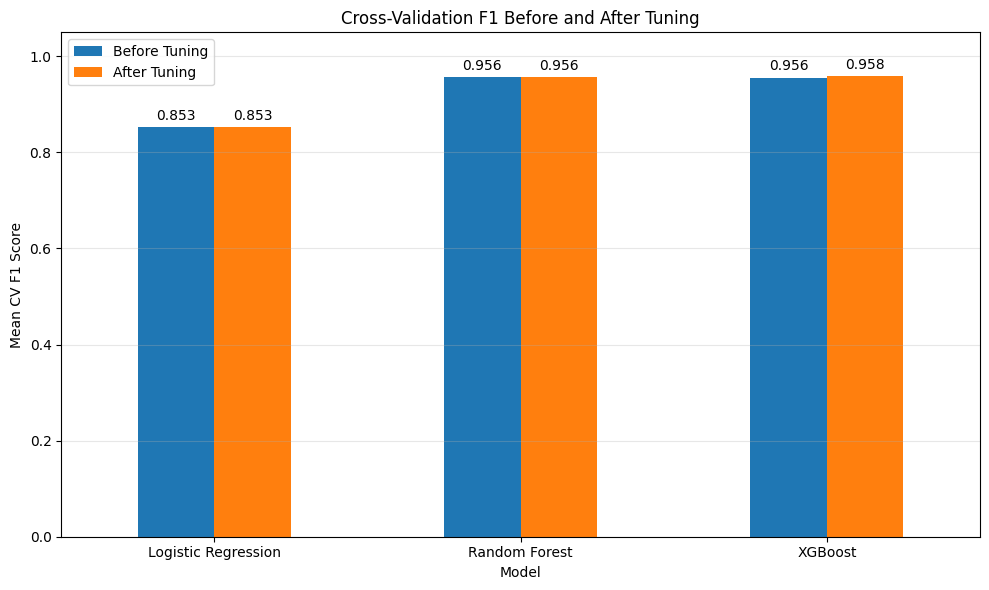


FINAL HYPERPARAMETER TUNING SUMMARY


,Model,Best CV F1,Test F1,Best Parameters
0,Logistic Regression,0.853103,0.850734,"{'clf__C': 0.1, 'clf__penalty': 'l2'}"
1,Random Forest,0.956316,0.957695,"{'clf__max_depth': None, 'clf__min_samples_spl..."
2,XGBoost,0.958071,0.959085,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."



BEST MODEL:
Model: XGBoost
Best CV F1: 0.9581
Test F1: 0.9591
Best Parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 7, 'clf__n_estimators': 200}


In [ ]:
# ============================================================

# PHASE 5 - BEFORE VS AFTER TUNING

# ============================================================

import matplotlib.pyplot as plt

comparison_rows = []

for name in models.keys():

    before = baseline_df.loc[

        baseline_df['Model'] == name,

        'CV F1'

    ].iloc[0]

    after = tuning_df.loc[

        tuning_df['Model'] == name,

        'Best CV F1'

    ].iloc[0]

    comparison_rows.append({

        'Model': name,

        'Before Tuning': before,

        'After Tuning': after,

        'Improvement': after - before

    })

tuning_comparison = pd.DataFrame(comparison_rows)

print("BEFORE VS AFTER HYPERPARAMETER TUNING")

display(tuning_comparison.round(4))

# Visualization

ax = tuning_comparison.set_index('Model')[

    ['Before Tuning', 'After Tuning']

].plot(

    kind='bar',

    figsize=(10, 6)

)

plt.title('Cross-Validation F1 Before and After Tuning')

plt.xlabel('Model')

plt.ylabel('Mean CV F1 Score')

plt.xticks(rotation=0)

plt.ylim(0, 1.05)

plt.legend()

plt.grid(axis='y', alpha=0.3)

for container in ax.containers:

    ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()

plt.show()

# Final summary

print("\nFINAL HYPERPARAMETER TUNING SUMMARY")

display(tuning_df[

    [

        'Model',

        'Best CV F1',

        'Test F1',

        'Best Parameters'

    ]

])

# Select best model using CV only

best_idx = tuning_df['Best CV F1'].idxmax()

best_row = tuning_df.loc[best_idx]

print("\nBEST MODEL:")

print("Model:", best_row['Model'])

print("Best CV F1:", round(best_row['Best CV F1'], 4))

print("Test F1:", round(best_row['Test F1'], 4))

print("Best Parameters:", best_row['Best Parameters'])

MODEL: Logistic Regression
                      precision    recall  f1-score   support

Neutral/Dissatisfied     0.8736    0.9017    0.8874     14573
           Satisfied     0.8690    0.8332    0.8507     11403

            accuracy                         0.8717     25976
           macro avg     0.8713    0.8675    0.8691     25976
        weighted avg     0.8716    0.8717    0.8713     25976

Confusion Matrix:
[[13141  1432]
 [ 1902  9501]]

MODEL: Random Forest
                      precision    recall  f1-score   support

Neutral/Dissatisfied     0.9564    0.9794    0.9678     14573
           Satisfied     0.9729    0.9430    0.9577     11403

            accuracy                         0.9634     25976
           macro avg     0.9647    0.9612    0.9627     25976
        weighted avg     0.9636    0.9634    0.9634     25976

Confusion Matrix:
[[14273   300]
 [  650 10753]]

MODEL: XGBoost
                      precision    recall  f1-score   support

Neutral/Dissatisfied    

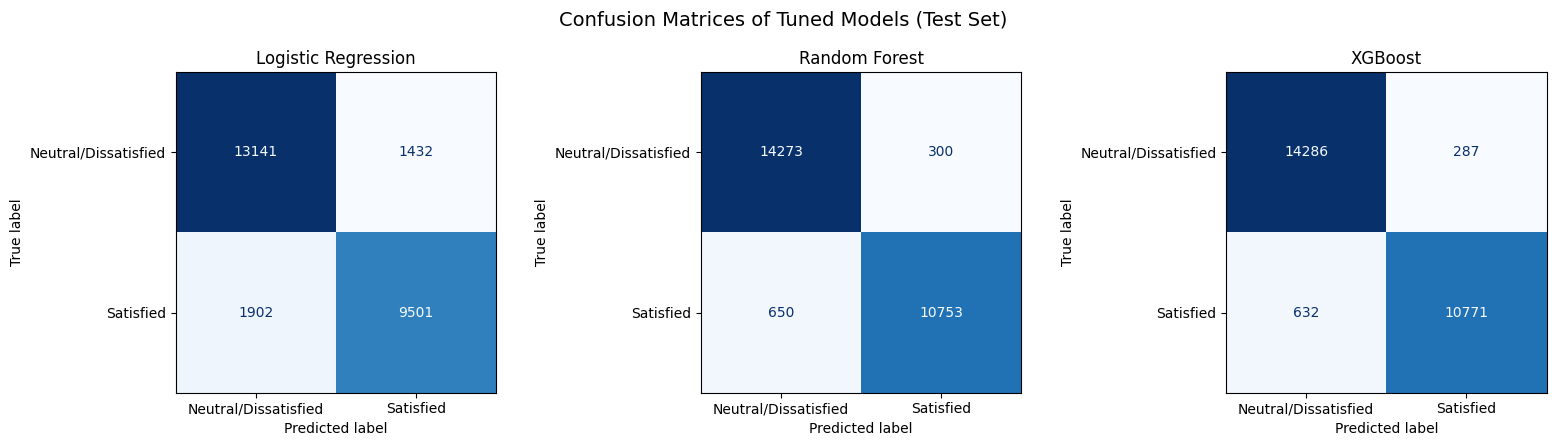

FINAL TEST SET PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-score
0,XGBoost,0.9646,0.9740,0.9446,0.9591
1,Random Forest,0.9634,0.9729,0.9430,0.9577
2,Logistic Regression,0.8717,0.8690,0.8332,0.8507



BEST MODEL SELECTION
Selection Method: 5-Fold Stratified Cross-Validation
Primary Metric: F1-score

Best Model: XGBoost
Cross-Validation F1-score: 0.9581
Independent Test F1-score: 0.9591

Best Hyperparameters:
{'clf__learning_rate': 0.1, 'clf__max_depth': 7, 'clf__n_estimators': 200}

Evaluation completed successfully!


In [ ]:
# ============================================================

# PHASE 5 - EVALUATION METRICS

# Final Evaluation of Tuned Models on the Independent Test Set

# ============================================================

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    confusion_matrix,

    ConfusionMatrixDisplay,

    classification_report

)

# Class labels

labels = ['Neutral/Dissatisfied', 'Satisfied']

# Store evaluation results

summary = []

# Create confusion matrix plots

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Evaluate each tuned model

for ax, (name, model) in zip(axes, best_models.items()):

    # Predict using the independent test set

    y_pred = model.predict(X_te)

    # Calculate evaluation metrics

    accuracy = accuracy_score(y_te, y_pred)

    precision = precision_score(

        y_te, y_pred, zero_division=0

    )

    recall = recall_score(

        y_te, y_pred, zero_division=0

    )

    f1 = f1_score(

        y_te, y_pred, zero_division=0

    )

    # Store results

    summary.append({

        'Model': name,

        'Accuracy': accuracy,

        'Precision': precision,

        'Recall': recall,

        'F1-score': f1

    })

    # Classification report

    print("=" * 60)

    print(f"MODEL: {name}")

    print("=" * 60)

    print(

        classification_report(

            y_te,

            y_pred,

            labels=[0, 1],

            target_names=labels,

            digits=4,

            zero_division=0

        )

    )

    # Confusion matrix

    cm = confusion_matrix(

        y_te,

        y_pred,

        labels=[0, 1]

    )

    print("Confusion Matrix:")

    print(cm)

    print()

    # Plot confusion matrix

    disp = ConfusionMatrixDisplay(

        confusion_matrix=cm,

        display_labels=labels

    )

    disp.plot(

        ax=ax,

        cmap='Blues',

        colorbar=False,

        values_format='d'

    )

    ax.set_title(name)

# Display confusion matrices

plt.suptitle(

    'Confusion Matrices of Tuned Models (Test Set)',

    fontsize=14

)

plt.tight_layout()

plt.show()

# ============================================================

# FINAL EVALUATION SUMMARY

# ============================================================

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(

    by='F1-score',

    ascending=False

).reset_index(drop=True)

print("=" * 60)

print("FINAL TEST SET PERFORMANCE")

print("=" * 60)

display(summary_df.round(4))

# ============================================================

# BEST MODEL SELECTION BASED ON CROSS-VALIDATION

# ============================================================

best_idx = tuning_df['Best CV F1'].idxmax()

best_model_name = tuning_df.loc[

    best_idx, 'Model'

]

best_cv_f1 = tuning_df.loc[

    best_idx, 'Best CV F1'

]

best_test_f1 = summary_df.loc[

    summary_df['Model'] == best_model_name,

    'F1-score'

].iloc[0]

print("\n" + "=" * 60)

print("BEST MODEL SELECTION")

print("=" * 60)

print("Selection Method: 5-Fold Stratified Cross-Validation")

print("Primary Metric: F1-score")

print(f"\nBest Model: {best_model_name}")

print(f"Cross-Validation F1-score: {best_cv_f1:.4f}")

print(f"Independent Test F1-score: {best_test_f1:.4f}")

print("\nBest Hyperparameters:")

print(tuning_df.loc[best_idx, 'Best Parameters'])

print("\nEvaluation completed successfully!")

In [ ]:
# ============================================================

# PHASE 6 - FINAL MODEL PERFORMANCE SUMMARY

# ============================================================

final_results = tuning_df[

    [

        'Model',

        'Best CV F1',

        'Test Accuracy',

        'Test Precision',

        'Test Recall',

        'Test F1'

    ]

].copy()

final_results = final_results.round(4)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(final_results)

FINAL MODEL PERFORMANCE COMPARISON


,Model,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.8531,0.8717,0.8690,0.8332,0.8507
1,Random Forest,0.9563,0.9634,0.9729,0.9430,0.9577
2,XGBoost,0.9581,0.9646,0.9740,0.9446,0.9591
